# 14: Fitting the digitised Karahadian et al. (2026) data

Notebook 13 used Karahadian et al.'s *procedure* but not their *points*, which are not tabulated. Here we digitise their Fig. 2 (`tools/digitize_karahadian_fig2.py` → `data/karahadian2026_fig2.csv`; 47 markers with error-bar caps, checked by overlay) and fit them directly.

**Status of the input:** this is a digitisation of a published raster figure (6720×5040 px, ~1 px ≈ 0.001 decade), not the authors' data. Where an error bar is hidden inside its marker, the marker half-height (0.0475 decade) is used as the uncertainty. Five deuteride points hidden behind the metal markers are missing (PdD 6.0; TiD 1.0, 3.5, 4.0, 5.5 keV).

Questions:
1. Does refitting the points reproduce the published $U_e$, and which yield model did the published curves use?
2. How model-dependent is $U_e$ (thin vs thick target)?
3. Does notebook 13's depth-artifact bound survive under the published model?
4. With real points, what screening ranges ℓ do the data allow for each profile shape, compared with the neutron bound?

In [1]:
import csv, numpy as np, matplotlib.pyplot as plt, warnings
from scipy import optimize
from PIL import Image
from beamfit import *
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"font.size":10})
BLUE, ORANGE, AQUA, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#e87ba4","#0b0b0b","#52514e"
ROWS = list(csv.DictReader(open("../data/karahadian2026_fig2.csv")))
def data(sample, emin=0.0, emax=6.4):
    d = [r for r in ROWS if r["sample"] == sample and emin <= float(r["E_cm_keV_nominal"]) <= emax]
    E = np.array([float(r["E_cm_keV_nominal"]) for r in d]); y = np.array([float(r["rel_yield"]) for r in d])
    hi = np.array([float(r["rel_yield_upper"]) for r in d]); lo = np.array([float(r["rel_yield_lower"]) for r in d])
    return E, y, np.maximum(np.maximum(np.log10(hi/y), np.log10(y/lo)), 0.0475)
FITWIN = {"Pd": 2.5, "PdD": 2.5, "Ti": 2.0, "TiD": 2.0}; PUB = {"Pd": 0.8, "PdD": 1.7, "Ti": 0.3, "TiD": 0.9}
for s in FITWIN:
    E, y, _ = data(s); print(f"{s:4s}: {len(E):2d} points digitised, {np.sum(E >= FITWIN[s])} in the fit window")

Pd  : 13 points digitised, 8 in the fit window
PdD : 12 points digitised, 7 in the fit window
Ti  : 13 points digitised, 9 in the fit window
TiD :  9 points digitised, 6 in the fit window


## 1. Which yield model did the published curves use?

We digitise the *curves* in Fig. 2(a) (bare and $U_e$ = 1.7 keV) between the markers and compare them with a thin-target cross-section ratio, $\sigma(E)/\sigma(6.5)$, and with thick-target integrals for stopping $S\propto E^p$.

In [2]:
W = "../data/_fig2_work"   # pdfimages output written by the digitiser (not committed)
import subprocess, os
os.makedirs(W, exist_ok=True)
if not os.path.exists(f"{W}/img-000.png"):
    subprocess.run(["pdfimages", "-png", "-f", "4", "-l", "4", "../.cache/fetch/arxiv_2512.06212.pdf", f"{W}/img"], check=True)
rgb = np.asarray(Image.open(f"{W}/img-000.png").convert("RGB")).astype(float)
al = np.asarray(Image.open(f"{W}/img-001.png")).astype(float)[..., None]/255
IMG = (rgb*al + 255*(1 - al)).astype(int)
X0, X1, Y0, Y1 = 804, 6451, 171, 4426
def curve(col, Es, tol=10):
    out = []
    for E in Es:
        x = int(round(X0 + E/6.5*(X1 - X0)))
        ys = np.where((np.abs(IMG[Y0+10:Y1-10, x-1:x+2] - np.array(col)).max(2) <= tol).any(1))[0]
        b = max(np.split(ys, np.where(np.diff(ys) > 2)[0] + 1), key=len)
        out.append(10**(-4*((Y0 + 10 + b.mean()) - Y0)/(Y1 - Y0)))
    return np.array(out)
EC = np.array([2.25, 2.75, 3.25, 3.75, 4.25, 4.75, 5.25, 5.75, 6.25])
bare_pub, red_pub = curve((0, 0, 0), EC), curve((139, 0, 0), EC)
rms = lambda a, b: np.sqrt(np.mean(np.log10(a/b)**2))
thin = lambda E, U=0.0: sig(E, U)/sig(E_NORM, U)
print(f"published bare curve vs thin-target ratio:      rms {rms(thin(EC), bare_pub):.3f} decade")
for p in [0.3, 0.5, 0.7, 1.0]:
    print(f"published bare curve vs thick target, S ~ E^{p}: rms {rms(rel(EC, p=p), bare_pub):.3f} decade")
U_red = optimize.minimize_scalar(lambda U: np.sum(np.log(thin(EC, U)/red_pub)**2), bounds=(0, 4), method="bounded").x
print(f"published '1.7 keV' curve = thin-target ratio with an energy shift of {U_red:.2f} keV (rms {rms(thin(EC, U_red), red_pub):.3f})")

published bare curve vs thin-target ratio:      rms 0.038 decade
published bare curve vs thick target, S ~ E^0.3: rms 0.270 decade
published bare curve vs thick target, S ~ E^0.5: rms 0.223 decade
published bare curve vs thick target, S ~ E^0.7: rms 0.176 decade
published bare curve vs thick target, S ~ E^1.0: rms 0.107 decade
published '1.7 keV' curve = thin-target ratio with an energy shift of 1.46 keV (rms 0.026)


## 2. $U_e$ from the digitised points under three yield models

In [3]:
MODELS = {
    "thin target, shift": lambda E, U: thin(E, U),
    "thick, S~E^0.5":     lambda E, U: rel(E, lambda e: f_shift(e, U), p=0.5),
    "thick, S~E^0.3":     lambda E, U: rel(E, lambda e: f_shift(e, U), p=0.3),
}
def fitU(sample, model):
    E, y, s = data(sample, FITWIN[sample]); m = MODELS[model]
    chi = lambda U: np.sum(((np.log10(m(E, U)) - np.log10(y))/s)**2)
    r = optimize.minimize_scalar(chi, bounds=(0.0, 6), method="bounded"); U, c0 = r.x, r.fun
    hi = optimize.brentq(lambda u: chi(u) - c0 - 1, U, 6)
    lo = optimize.brentq(lambda u: chi(u) - c0 - 1, 0.0, U) if chi(0.0) > c0 + 1 else 0.0   # U < 0 undefined below 1 keV for thick target
    return U, U - lo, hi - U, c0, len(E) - 1
UFIT = {}
print(f"{'sample':6s} {'published':>9s}  " + "  ".join(f"{m:>24s}" for m in MODELS))
for s in FITWIN:
    cells = []
    for m in MODELS:
        U, el, eh, c, dof = fitU(s, m); UFIT[(s, m)] = U
        cells.append(f"{U:5.2f} -{el:.2f}/+{eh:.2f} χ²={c:4.1f}/{dof}")
    print(f"{s:6s} {PUB[s]:9.1f}  " + "  ".join(f"{c:>24s}" for c in cells))
ratio = [PUB[s]/UFIT[(s, 'thin target, shift')] for s in ["Pd", "PdD", "TiD"]]
print(f"\npublished / thin-shift fit (Pd, PdD, TiD): {', '.join(f'{r:.2f}' for r in ratio)};  published 1.7 / shift on their curve: {1.7/U_red:.2f}")

sample published        thin target, shift            thick, S~E^0.5            thick, S~E^0.3


Pd           0.8   0.63 -0.09/+0.10 χ²= 2.8/7   1.08 -0.10/+0.10 χ²= 3.3/7   1.20 -0.10/+0.11 χ²= 3.5/7
PdD          1.7   1.39 -0.13/+0.13 χ²= 2.2/6   1.86 -0.12/+0.12 χ²= 3.5/6   2.03 -0.13/+0.13 χ²= 3.7/6


Ti           0.3   0.41 -0.07/+0.07 χ²= 8.8/8   0.85 -0.07/+0.07 χ²=11.1/8   0.96 -0.08/+0.08 χ²=11.9/8
TiD          0.9   0.76 -0.06/+0.06 χ²= 2.6/5   1.16 -0.06/+0.07 χ²= 5.8/5   1.27 -0.07/+0.07 χ²= 6.6/5

published / thin-shift fit (Pd, PdD, TiD): 1.28, 1.22, 1.18;  published 1.7 / shift on their curve: 1.16


## 3. Does the depth-artifact bound survive under the published (thin-target) model?

Notebook 13 asked how much $U_e$ a near-surface deuterium excess can fake when the yields are fitted with a *thick*-target model. If the fit model is effectively thin-target, the relevant question is: what does a thin-target fit return for (a) a real thick target with uniform deuterium and no screening, and (b) the extreme surface excess (all yield from the surface, i.e. a thin target)?

In [4]:
Ef = np.linspace(2.5, 6.0, 8)
def fit_thin(y):
    return optimize.minimize_scalar(lambda U: np.sum((np.log10(thin(Ef, U)) - np.log10(y))**2), bounds=(-3, 6), method="bounded").x
for p in [0.3, 0.5, 0.7]:
    print(f"S ~ E^{p}: uniform thick target, no screening -> thin-target fit U = {fit_thin(rel(Ef, p=p))*1e3:6.0f} eV;  "
          f"extreme surface excess -> {fit_thin(thin(Ef))*1e3:4.0f} eV")

S ~ E^0.3: uniform thick target, no screening -> thin-target fit U =   -377 eV;  extreme surface excess ->    0 eV
S ~ E^0.5: uniform thick target, no screening -> thin-target fit U =   -324 eV;  extreme surface excess ->    0 eV
S ~ E^0.7: uniform thick target, no screening -> thin-target fit U =   -268 eV;  extreme surface excess ->    0 eV


## 4. Screening shapes fitted to the points

For each profile shape and range ℓ, the strength ΔU is fitted to the PdD (and Pd) points, using the WKB enhancement of $V = e^2/R - \Delta U\,g(R/\ell)$ in the physical thick-target model ($S\propto E^{0.5}$) and, for comparison, in the thin-target model. The data allow a range when $\chi^2(\ell) - \chi^2_{\min} < 4$ (≈2σ, one parameter). Long ranges (ℓ ≫ turning point) are indistinguishable from a constant $U_e$.

In [5]:
ELL = np.logspace(np.log10(0.0015), np.log10(0.1), 26)
def profile_chi2(sample, shape, model):
    E, y, s = data(sample, FITWIN[sample]); out = []
    for ell in ELL:
        def chi(lg):
            fe = fenh_profile(10**lg, ell*1e5, shape)
            yy = rel(E, fe) if model == "thick" else fe(E)*sig(E)/(fe(E_NORM)*sig(E_NORM))
            return np.sum(((np.log10(yy) - np.log10(y))/s)**2)
        r = optimize.minimize_scalar(chi, bounds=(-1.5, 2.5), method="bounded")
        out.append((r.fun, 10**r.x))
    return np.array(out)
CH = {}
for sample in ["PdD", "Pd"]:
    for model in (["thick", "thin"] if sample == "PdD" else ["thick"]):
        print(f"\n{sample}, {model}-target model: smallest ℓ allowed (Δχ² < 4) and χ² at that ℓ / at ℓ = 0.1 Å")
        for shape in PROFILES:
            c = profile_chi2(sample, shape, model); CH[(sample, model, shape)] = c
            ok = np.where(c[:, 0] - c[:, 0].min() < 4)[0]
            print(f"   {shape:12s} ℓ_min = {ELL[ok[0]]:.4f} Å   χ² {c[ok[0], 0]:5.1f} / {c[-1, 0]:5.1f}   ΔU at ℓ_min = {c[ok[0], 1]:6.2f} keV")


PdD, thick-target model: smallest ℓ allowed (Δχ² < 4) and χ² at that ℓ / at ℓ = 0.1 Å


   exponential  ℓ_min = 0.0021 Å   χ²   5.3 /   3.3   ΔU at ℓ_min =   8.57 keV


   gaussian     ℓ_min = 0.0041 Å   χ²   3.2 /   3.5   ΔU at ℓ_min =   3.52 keV


   step         ℓ_min = 0.0041 Å   χ²   5.2 /   3.5   ΔU at ℓ_min =   2.46 keV


   yukawa       ℓ_min = 0.0015 Å   χ²   1.9 /   3.4   ΔU at ℓ_min =   4.66 keV

PdD, thin-target model: smallest ℓ allowed (Δχ² < 4) and χ² at that ℓ / at ℓ = 0.1 Å


...

   yukawa       ℓ_min = 0.0015 Å   χ²   1.8 /   2.2   ΔU at ℓ_min =   3.22 keV

Pd, thick-target model: smallest ℓ allowed (Δχ² < 4) and χ² at that ℓ / at ℓ = 0.1 Å


   exponential  ℓ_min = 0.0025 Å   χ²   5.5 /   3.2   ΔU at ℓ_min =   4.90 keV


   gaussian     ℓ_min = 0.0041 Å   χ²   6.6 /   3.3   ΔU at ℓ_min =   2.46 keV


   step         ℓ_min = 0.0049 Å   χ²   4.5 /   3.3   ΔU at ℓ_min =   1.34 keV


   yukawa       ℓ_min = 0.0015 Å   χ²   2.9 /   3.3   ΔU at ℓ_min =   3.00 keV


In [6]:
NEUTRON = {"yukawa": 0.0045, "exponential": 0.118, "gaussian": 0.266, "step": np.nan}   # notebook 13, 1.7 keV, 2.75 Å
print("PdD at rest, 2.75 Å lattice: allowed window = [data ℓ_min (thick model), neutron ℓ_max]")
for shape in PROFILES:
    c = CH[("PdD", "thick", shape)]; ok = np.where(c[:, 0] - c[:, 0].min() < 4)[0]; lmin = ELL[ok[0]]
    lmax = NEUTRON[shape]
    state = "no bound from neutrons at 2.75 Å" if not np.isfinite(lmax) else ("EMPTY" if lmin >= lmax else f"{lmin:.4f}–{lmax:.4f} Å")
    print(f"   {shape:12s} {state}")

PdD at rest, 2.75 Å lattice: allowed window = [data ℓ_min (thick model), neutron ℓ_max]
   exponential  0.0021–0.1180 Å
   gaussian     0.0041–0.2660 Å
   step         no bound from neutrons at 2.75 Å
   yukawa       0.0015–0.0045 Å


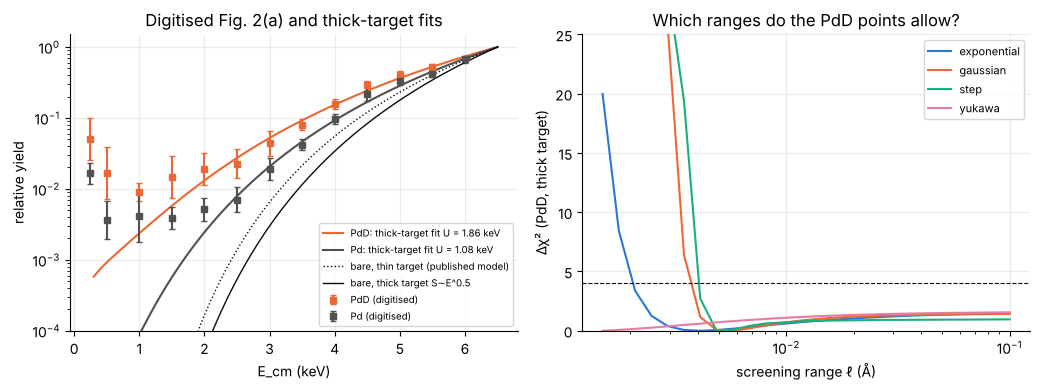

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
Eall = np.linspace(0.3, 6.5, 200)
for s, c in [("PdD", ORANGE), ("Pd", MUTED)]:
    E, y, sg = data(s); ax[0].errorbar(E, y, yerr=[y*(1 - 10**-sg), y*(10**sg - 1)], fmt="s", color=c, ms=4, capsize=2, label=f"{s} (digitised)")
    ax[0].plot(Eall, rel(Eall, lambda e: f_shift(e, UFIT[(s, 'thick, S~E^0.5')])), color=c, lw=1.5, label=f"{s}: thick-target fit U = {UFIT[(s, 'thick, S~E^0.5')]:.2f} keV")
ax[0].plot(Eall, thin(Eall), color=INK, ls=":", lw=1, label="bare, thin target (published model)")
ax[0].plot(Eall, rel(Eall), color=INK, lw=1, label="bare, thick target S∼E^0.5")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-4, 1.5); ax[0].set_xlabel("E_cm (keV)"); ax[0].set_ylabel("relative yield")
ax[0].legend(fontsize=7); ax[0].set_title("Digitised Fig. 2(a) and thick-target fits")
for shape, c in zip(PROFILES, [BLUE, ORANGE, AQUA, MAGENTA]):
    ch = CH[("PdD", "thick", shape)][:, 0]; ax[1].plot(ELL, ch - ch.min(), color=c, label=shape)
ax[1].axhline(4, color=INK, ls="--", lw=.8); ax[1].set_xscale("log"); ax[1].set_ylim(0, 25)
ax[1].set_xlabel("screening range ℓ (Å)"); ax[1].set_ylabel("Δχ² (PdD, thick target)"); ax[1].legend(fontsize=8)
ax[1].set_title("Which ranges do the PdD points allow?")
plt.tight_layout(); plt.savefig("../figures/14_digitised_fits.png", dpi=160); plt.show()

## Interpretation

Numbers from the printed results above. The input is a digitisation, not tabulated data.

1. **The published model curves are thin-target cross-section ratios.** The published bare curve matches $\sigma(E)/\sigma(6.5)$ to 0.038 decade. Thick-target integrals with $S\propto E^{0.3\text{–}1.0}$ miss it by 0.11–0.27 decade, although the caption says "thick-target yield calculations". The published "1.7 keV" curve is a thin-target ratio with an energy shift of 1.46 keV. Their $U_e$ convention therefore runs ~1.16× our energy-shift value, and our thin-target fits of the digitised points reproduce the published values with the same factor (1.18–1.28 for Pd, PdD and TiD). Ti does not follow it (0.41 vs 0.3; χ² 8.8/8).
2. **$U_e$ is model-dependent by more than its quoted ±0.2 keV.** From the same points: thin target 0.63 / 1.39 / 0.41 / 0.76 keV; thick target with $S\propto E^{0.5}$ 1.08 / 1.86 / 0.85 / 1.16 keV (Pd / PdD / Ti / TiD); and with $S\propto E^{0.3}$ up to 2.03 keV for PdD. A physical thick-target analysis gives **higher** screening than published, by 0.16–0.55 keV.
3. **The depth-artifact conclusion gets stronger under the published model.** Fitted with a thin-target model, a uniform thick target with no screening returns $U$ = −0.27 to −0.38 keV, and the most extreme surface excess returns exactly 0. So under the published convention, no depth profile can fake *any* positive screening. Under the thick-target convention, the limit is 0.28–0.44 keV (notebook 13). Either way the keV values are genuine enhancements.
4. **The points barely constrain the screening shape.** Every shape fits PdD within Δχ² < 4 down to ranges at the turning-point scale: exponential 0.0021 Å, Gaussian 0.0041 Å, step 0.0041–0.0049 Å, Yukawa down to the grid edge (0.0015 Å). Combined with the neutron bound on a 2.75 Å lattice, the allowed windows at rest are 0.0021–0.118 Å (exponential), 0.0041–0.266 Å (Gaussian) and 0.0015–0.0045 Å (Yukawa). For the long-tailed Yukawa shape the window is pinned to the beam turning point.

**Consequences.** (i) Claims A and B use $U_e$ up to 2.0 keV, which covers the thick-target refit (1.86 keV with $S\propto E^{0.5}$; 2.03 keV with $E^{0.3}$ is within 2%). (ii) The yield-model question is worth raising with the authors before publication; it moves their $U_e$ by more than its error. (iii) The tabulated points with errors would replace this digitisation.